# Structural Equation Modeling (SEM) dengan Studi Kasus
**TI5002 Analisis Statistik · Minggu 6** — kronologi analisis dari awal sampai akhir

**Kasus:** sebuah perusahaan ingin meningkatkan retensi dan produktivitas pegawai. Peneliti ingin tahu bagaimana *coworker attitude*, *work environment*, dan *pay level* memengaruhi *job satisfaction*, *organizational commitment*, dan *probability of employee turnover* (contoh di slide "Contoh SEM Sederhana").

**Data:** `data_sem_sikap_karyawan.xlsx` (simulasi, 450 responden, 18 butir Likert 1–7). Letakkan file itu di folder yang sama dengan notebook ini.

| Langkah di slide | Isi di notebook |
|---|---|
| 1. Develop a theoretically based model | Bagian 1 |
| 2. Construct a path diagram | Bagian 2 |
| 3. Convert the path diagram | Bagian 3 |
| 4. Input (asumsi, missing data, ukuran sampel) | Bagian 4 |
| 5. Assess identification | Bagian 5 |
| 6. Estimasi & goodness-of-fit | Bagian 6 |
| 7. Interpretasi & modifikasi model | Bagian 7 |

**Berkas pendukung:** `sem_helpers.py` (modul custom untuk output yang tidak disediakan semopy) harus berada di folder yang sama.


In [1]:
# Jalankan sekali jika semopy belum terpasang:
# !pip install semopy openpyxl

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from scipy import stats
import semopy
import sem_helpers as sh     # modul custom: Mardia, alpha/CR/AVE, R², efek, tabel fit, dll. (file sem_helpers.py)

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
pd.set_option("display.width", 140)
plt.rcParams["figure.dpi"] = 110

## 1. Kembangkan model berbasis teori
SEM bersifat **konfirmatori**: hubungan sebab-akibat ditentukan oleh **justifikasi teoritis**, bukan oleh hasil hitungan. Slide memberi 4 kriteria kausal, dan kita periksa satu per satu untuk kasus ini:

1. **Asosiasi cukup** antara dua variabel → akan dicek dari korelasi data (Bagian 4).
2. **Urutan waktu**: sebab mendahului akibat. Kondisi kerja (rekan, lingkungan, gaji) ada lebih dulu daripada sikap; kepuasan kerja mendahului komitmen, dan keduanya mendahului niat keluar.
3. **Tidak ada variabel penyebab alternatif** yang diabaikan → risiko *specification error*. Ini keterbatasan: faktor lain (mis. gaya kepemimpinan) tidak ada di model.
4. **Dasar teori** untuk hubungannya (literatur kepuasan kerja dan turnover).

**Hipotesis (jalur struktural):**

| | Jalur | Tanda yang diharapkan |
|---|---|---|
| H1 | Coworker Attitude → Job Satisfaction | + |
| H2 | Work Environment → Job Satisfaction | + |
| H3 | Job Satisfaction → Organizational Commitment | + |
| H4 | Pay Level → Organizational Commitment | + |
| H5 | Job Satisfaction → Probability of Turnover | − |
| H6 | Organizational Commitment → Probability of Turnover | − |

Ketiga konstruk eksogen (CW, WE, PAY) dibiarkan **saling berkorelasi** (panah lengkung).

## 2. Bangun path diagram
Aturan di slide: panah lurus satu kepala = hubungan kausal langsung; panah lengkung = korelasi; konstruk **eksogen** tidak menerima panah masuk, konstruk **endogen** diprediksi oleh konstruk lain.

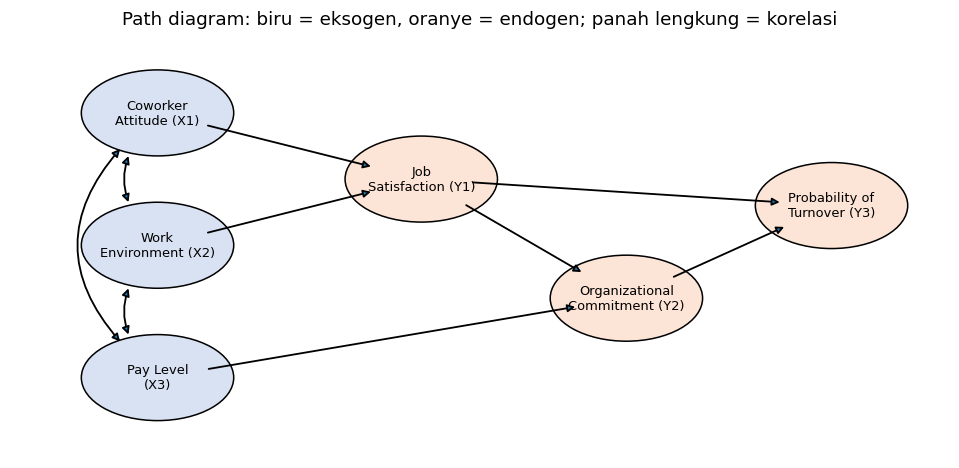

In [2]:
pos = {"CW":(0,4), "WE":(0,2), "PAY":(0,0), "JS":(4.5,3), "OC":(8,1.2), "TO":(11.5,2.6)}
label = {"CW":"Coworker\nAttitude (X1)", "WE":"Work\nEnvironment (X2)", "PAY":"Pay Level\n(X3)",
         "JS":"Job\nSatisfaction (Y1)", "OC":"Organizational\nCommitment (Y2)", "TO":"Probability of\nTurnover (Y3)"}
paths = [("CW","JS"), ("WE","JS"), ("JS","OC"), ("PAY","OC"), ("JS","TO"), ("OC","TO")]

fig, ax = plt.subplots(figsize=(11, 5))
w, h = 2.6, 1.3
for k, (x, y) in pos.items():
    ax.add_patch(Ellipse((x, y), w, h, fc="#D9E2F3" if k in ("CW","WE","PAY") else "#FCE4D6", ec="k"))
    ax.text(x, y, label[k], ha="center", va="center", fontsize=8.5)
def edge(a, b, rad=0.0, both=False):
    (x1, y1), (x2, y2) = pos[a], pos[b]
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle="<|-|>" if both else "-|>", shrinkA=34, shrinkB=34,
                                connectionstyle=f"arc3,rad={rad}", lw=1.2))
for a, b in paths: edge(a, b)
edge("CW", "WE", rad=0.5, both=True); edge("WE", "PAY", rad=0.5, both=True); edge("CW", "PAY", rad=0.6, both=True)
ax.set_xlim(-2.5, 13.5); ax.set_ylim(-1.2, 5.2); ax.axis("off")
ax.set_title("Path diagram: biru = eksogen, oranye = endogen; panah lengkung = korelasi")
plt.show()

## 3. Konversi path diagram: measurement model & structural model
**Measurement model** menetapkan indikator mana yang mengukur konstruk mana (konstruk *reflective*: indikator adalah cerminan konstruk). Tiap konstruk punya 3 indikator, dan setiap indikator hanya dimuat pada **satu** konstruk yang ditetapkan peneliti (beda dengan analisis faktor eksploratori yang memuat semua indikator pada semua faktor).

$$X = \Lambda_x \xi + \delta \qquad Y = \Lambda_y \eta + \varepsilon$$

**Structural model** menghubungkan konstruk:

$$\eta = B\eta + \Gamma\xi + \zeta$$

dengan $\xi = (CW, WE, PAY)'$, $\eta = (JS, OC, TO)'$, dan

$$B=\begin{bmatrix}0&0&0\\ \beta_{21}&0&0\\ \beta_{31}&\beta_{32}&0\end{bmatrix},\quad
\Gamma=\begin{bmatrix}\gamma_{11}&\gamma_{12}&0\\ 0&0&\gamma_{23}\\ 0&0&0\end{bmatrix}$$

Angka 0 berarti jalur itu tidak ada dalam teori kita. Sintaks `semopy`: `=~` untuk "diukur oleh", `~` untuk regresi struktural, `~~` untuk kovarians.

In [3]:
model_A = """
# --- Measurement model ---
CW  =~ CW1 + CW2 + CW3
WE  =~ WE1 + WE2 + WE3
PAY =~ PAY1 + PAY2 + PAY3
JS  =~ JS1 + JS2 + JS3
OC  =~ OC1 + OC2 + OC3
TO  =~ TO1 + TO2 + TO3

# --- Structural model ---
JS ~ CW + WE
OC ~ JS + PAY
TO ~ JS + OC

# --- Korelasi antar konstruk eksogen ---
CW ~~ WE
CW ~~ PAY
WE ~~ PAY
"""

constructs = ["CW", "WE", "PAY", "JS", "OC", "TO"]
exo, endo = ["CW", "WE", "PAY"], ["JS", "OC", "TO"]
items = [f"{c}{i}" for c in constructs for i in (1, 2, 3)]
struct_paths = [("CW","JS"), ("WE","JS"), ("JS","OC"), ("PAY","OC"), ("JS","TO"), ("OC","TO")]

# Hitung jumlah parameter bebas (t). Konvensi: loading indikator pertama tiap konstruk dikunci = 1.
n_ind = len(items)
t_table = pd.Series({
    "Loading bebas (18 - 6 dikunci = 1)": n_ind - len(constructs),
    "Variansi error pengukuran (δ, ε)": n_ind,
    "Koefisien jalur struktural (β, γ)": len(struct_paths),
    "Variansi konstruk eksogen (φ)": len(exo),
    "Kovarians antar eksogen (φ)": 3,
    "Variansi error struktural (ζ)": len(endo),
})
t = int(t_table.sum())
print(t_table.to_string()); print("-"*45); print("Total parameter yang diestimasi t =", t)

Loading bebas (18 - 6 dikunci = 1)    12
Variansi error pengukuran (δ, ε)      18
Koefisien jalur struktural (β, γ)      6
Variansi konstruk eksogen (φ)          3
Kovarians antar eksogen (φ)            3
Variansi error struktural (ζ)          3
---------------------------------------------
Total parameter yang diestimasi t = 45


## 4. Input: data, asumsi, dan ukuran sampel
### 4a. Muat data & cek data hilang
SEM sebaiknya memakai data lengkap; penanganan *missing data* dilakukan pada tahap *data screening* (minggu 2).

In [4]:
df = pd.read_excel("data_sem_sikap_karyawan.xlsx", sheet_name="Data")
X = df[items]
print("Ukuran data:", df.shape)
print("Jumlah data hilang:", int(X.isna().sum().sum()))
X.describe().T[["count", "mean", "std", "min", "max"]]

Ukuran data: (450, 19)
Jumlah data hilang: 0


,count,mean,std,min,max
CW1,450.000,5.202,1.249,2.000,7.000
CW2,450.000,5.227,1.226,1.000,7.000
CW3,450.000,5.191,1.269,2.000,7.000
WE1,450.000,4.689,1.274,1.000,7.000
WE2,450.000,4.747,1.276,1.000,7.000
WE3,450.000,4.762,1.283,1.000,7.000
PAY1,450.000,4.040,1.237,1.000,7.000
PAY2,450.000,4.098,1.389,1.000,7.000
PAY3,450.000,4.042,1.383,1.000,7.000
JS1,450.000,4.920,1.312,1.000,7.000


### 4b. Asumsi: normalitas, linieritas, independensi
Estimasi *maximum likelihood* mengasumsikan normalitas multivariat. Cek: skewness, kurtosis tiap butir, dan uji **Mardia** (kurtosis multivariat). Independensi dan random sampling adalah asumsi desain (tidak bisa diuji dari data); linieritas dilihat dari korelasi/scatter.

In [5]:
norm_tbl = sh.skew_kurt(X)
bad = norm_tbl[(norm_tbl["skewness"].abs() > 1) | (norm_tbl["kurtosis"].abs() > 2)]
print("Butir dengan |skew|>1 atau |kurtosis|>2:", list(bad.index) or "tidak ada")

m = sh.mardia_kurtosis(X)
print(f"Mardia kurtosis = {m['b2p']:.2f} (harapan jika normal = {m['expected']}), z = {m['z']:.2f}, p = {m['p_value']:.3f}")
norm_tbl.T

Butir dengan |skew|>1 atau |kurtosis|>2: tidak ada
Mardia kurtosis = 354.64 (harapan jika normal = 360), z = -2.12, p = 0.034


,CW1,CW2,CW3,WE1,WE2,WE3,PAY1,PAY2,PAY3,JS1,JS2,JS3,OC1,OC2,OC3,TO1,TO2,TO3
skewness,-0.318,-0.249,-0.225,-0.167,-0.162,-0.221,-0.026,-0.070,-0.010,-0.225,-0.132,-0.278,-0.224,-0.169,-0.054,0.063,0.117,0.151
kurtosis,-0.533,-0.459,-0.808,-0.428,-0.364,-0.392,-0.301,-0.204,-0.537,-0.442,-0.449,-0.247,-0.344,-0.420,-0.319,-0.565,-0.387,-0.519


Pada data ini nilai Mardia sedikit di bawah harapan (z negatif): ekor distribusi *lebih ringan* dari normal karena skala Likert dibatasi 1–7, bukan ekor berat. Itu tidak berbahaya bagi estimasi ML.

Data Likert 1–7 bersifat diskret sehingga normalitas multivariat tidak pernah sempurna. Pedoman praktis: selama skewness/kurtosis tiap butir moderat, estimasi ML cukup andal. Bila data **jauh dari normal**, slide menyarankan menaikkan rasio sampel menjadi 15:1 atau memakai estimator yang robust.

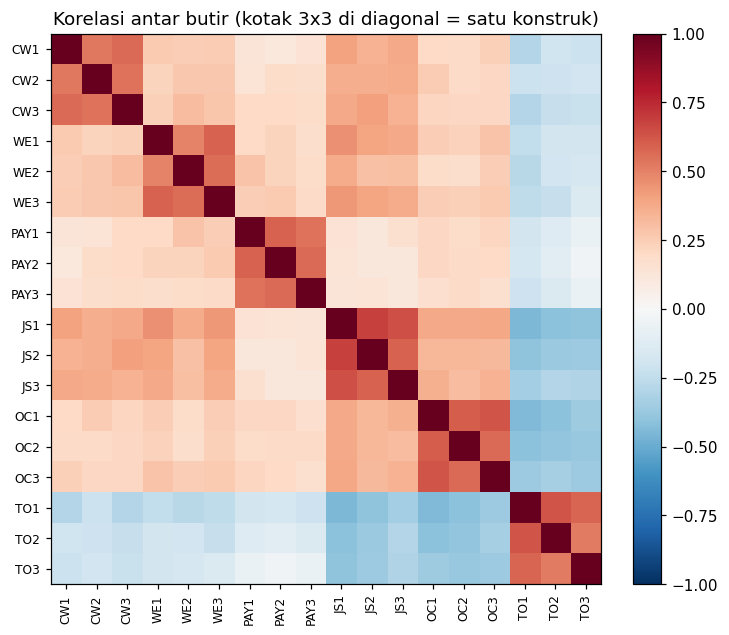

In [6]:
corr = X.corr()
fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(n_ind)); ax.set_xticklabels(items, rotation=90, fontsize=8)
ax.set_yticks(range(n_ind)); ax.set_yticklabels(items, fontsize=8)
plt.colorbar(im, fraction=0.046); ax.set_title("Korelasi antar butir (kotak 3x3 di diagonal = satu konstruk)")
plt.show()

Terbaca pola yang diharapkan: butir dalam satu konstruk berkorelasi tinggi (kriteria kausal 1: ada asosiasi), butir TO berkorelasi negatif dengan konstruk lain.

### 4c. Ukuran sampel
Pedoman slide: minimum **5 responden per parameter** (ideal 10:1; 15:1 bila data tidak normal); ML butuh minimum 100; secara umum 200 cukup, tetapi sampel yang terlalu besar membuat uji χ² terlalu sensitif.

In [7]:
n = len(df)
pd.DataFrame({"Rasio": ["5:1 (minimum)", "10:1 (ideal)", "15:1 (data non-normal)"],
              "Sampel dibutuhkan": [5*t, 10*t, 15*t],
              "n kita": n,
              "Terpenuhi?": ["ya" if n >= k*t else "tidak" for k in (5, 10, 15)]})

,Rasio,Sampel dibutuhkan,n kita,Terpenuhi?
0,5:1 (minimum),225,450,ya
1,10:1 (ideal),450,450,ya
2,15:1 (data non-normal),675,450,tidak


Dengan *t* = 45, n = 450 memenuhi rasio 10:1 (ideal) tetapi belum 15:1. Karena distribusi butir mendekati normal, ini cukup.

### 4d. Mini-demo: korelasi sebagai *compound paths*
Slide memperlihatkan bahwa korelasi antar variabel adalah jumlah jalur langsung dan tidak langsung (X1↔X2 = A, X1→Y1 = B, X2→Y1 = C): r(x1,x2) = A, r(x1,Y1) = B + AC, r(x2,Y1) = C + AB. Inilah ide dasar estimasi koefisien struktural:

In [8]:
A = 0.5
M = np.array([[1, A], [A, 1]])          # B + A*C = 0.6 ; A*B + C = 0.7
B_, C_ = np.linalg.solve(M, [0.6, 0.7])
print(f"A = {A}, B = {B_:.2f}, C = {C_:.2f}   (sesuai slide: B = 0.33, C = 0.53)")

A = 0.5, B = 0.33, C = 0.53   (sesuai slide: B = 0.33, C = 0.53)


## 5. Identifikasi model (derajat bebas)
Model harus punya cukup informasi untuk menghasilkan estimasi yang unik. Informasi yang tersedia = elemen unik matriks kovarians indikator: $\tfrac12 (p+q)(p+q+1)$, dengan $p+q = 18$ indikator. Parameter yang diestimasi = $t$.

$$df = \tfrac12 (p+q)(p+q+1) - t$$

- df > 0: *over-identified* (tujuan yang harus dicapai)
- df = 0: *just-identified* (tidak ada generalizability)
- df < 0: *under-identified* (tidak ada estimasi unik)

In [9]:
pq = n_ind
moments = pq * (pq + 1) // 2
dof = moments - t
status = "over-identified" if dof > 0 else "just-identified" if dof == 0 else "under-identified"
print(f"Elemen unik matriks kovarians = {pq}*{pq+1}/2 = {moments}")
print(f"Parameter t = {t}")
print(f"df = {moments} - {t} = {dof}  ->  {status}")

Elemen unik matriks kovarians = 18*19/2 = 171
Parameter t = 45
df = 171 - 45 = 126  ->  over-identified


Model **over-identified** (df = 126), sehingga fit model bisa diuji: semakin banyak "kendala" (jalur yang kita yakini tidak ada) yang ternyata sesuai dengan data, semakin kuat modelnya. Nilai ini nanti harus sama dengan `DoF` dari `semopy`.

## 6. Estimasi dan evaluasi goodness-of-fit
Metode **maximum likelihood**: cari parameter θ yang meminimumkan selisih antara matriks kovarians sampel **S** dan matriks kovarians implikasi model **Σ(θ)**.

In [10]:
model = semopy.Model(model_A)
res = model.fit(X)            # default: maximum likelihood
print(res)
est = sh.annotate_estimates(model.inspect(std_est=True), items, constructs)
est

Name of objective: MLW
Optimization method: SLSQP
Optimization successful.
Optimization terminated successfully
Objective value: 0.280
Number of iterations: 28
Params: 0.944 1.048 0.928 1.088 1.168 1.066 0.886 0.847 0.952 0.930 0.898 0.857 0.510 0.523 0.459 0.231 -0.342 -0.453 0.409 0.238 0.856 0.336 0.891 0.700 0.736 0.668 0.604 0.429 0.601 0.749 0.669 0.530 0.729 0.649 0.867 0.660 0.741 0.922 0.551 0.505 0.692 0.835 0.728 0.857 0.590


,lval,op,rval,Estimate,Est. Std,Std. Err,z-value,p-value,kind,a,b
0,JS,~,CW,0.510,0.416,0.072,7.128,0.000,path,CW,JS
1,JS,~,WE,0.523,0.435,0.070,7.477,0.000,path,WE,JS
2,OC,~,JS,0.459,0.509,0.050,9.224,0.000,path,JS,OC
3,OC,~,PAY,0.231,0.210,0.059,3.899,0.000,path,PAY,OC
4,TO,~,JS,-0.342,-0.366,0.056,-6.104,0.000,path,JS,TO
5,TO,~,OC,-0.453,-0.438,0.065,-6.970,0.000,path,OC,TO
6,CW1,~,CW,1.000,0.742,NaN,NaN,NaN,loading,CW,CW1
7,CW2,~,CW,0.944,0.714,0.073,12.947,0.000,loading,CW,CW2
8,CW3,~,CW,1.048,0.765,0.078,13.461,0.000,loading,CW,CW3
9,WE1,~,WE,1.000,0.742,NaN,NaN,NaN,loading,WE,WE1


### 6a. Cek *offending estimates* dulu
Sebelum menilai fit, periksa estimasi yang tidak masuk akal: **variansi error negatif** (*Heywood case*), **koefisien standar ≥ 1**, atau **standard error sangat besar**.

In [11]:
off = sh.offending_estimates(est)
print("Variansi error negatif :", len(off["variansi_negatif"]))
print("Loading standar >= 0.95 :", len(off["loading_terlalu_tinggi"]))
print("Standard error > 1      :", len(off["se_besar"]))

Variansi error negatif : 0
Loading standar >= 0.95 : 0
Standard error > 1      : 0


Bila ketiganya nol, model layak dievaluasi lebih lanjut. Jika ada yang muncul, perbaiki dulu (mis. buang indikator bermasalah, tetapkan kendala) sebelum menafsirkan fit.

### 6b. Goodness-of-fit
Slide membagi ukuran fit menjadi tiga: **absolute** (χ², RMSEA, GFI), **incremental** (CFI, TLI, NFI; dibandingkan dengan model dasar), dan **parsimonious** (mengoreksi jumlah parameter; AIC/BIC, dan RMSEA juga memperhitungkannya).

In [12]:
fit = semopy.calc_stats(model).iloc[0]
print(f"DoF semopy = {int(fit['DoF'])}   (harus sama dengan hitungan manual = {dof})")
print(f"chi2 = {fit['chi2']:.2f}   AIC = {fit['AIC']:.1f}   BIC = {fit['BIC']:.1f}")
sh.fit_table(fit)

DoF semopy = 126   (harus sama dengan hitungan manual = 126)
chi2 = 125.84   AIC = 89.4   BIC = 274.4


,Nilai,Kriteria,Lolos?
chi2 p-value,0.487,"p > 0,05",ya
CFI,1.000,"≥ 0,90 (baik ≥ 0,95)",ya
TLI,1.000,"≥ 0,90 (baik ≥ 0,95)",ya
GFI,0.964,"≥ 0,90",ya
NFI,0.964,"≥ 0,90",ya
RMSEA,0.000,"≤ 0,08 (baik ≤ 0,06)",ya


**Cara membaca:** χ² menguji H0 "Σ(θ) = Σ" sehingga di sini kita *berharap tidak menolak* (p > 0,05). Namun χ² sangat sensitif terhadap ukuran sampel; pada n besar, penyimpangan kecil sekalipun bisa signifikan. Karena itu χ² dibaca bersama CFI/TLI/RMSEA, tidak sendirian.

### 6c. Measurement model fit: loading, reliabilitas, validitas konvergen
Slide: kecocokan measurement model dinilai lewat reliabilitas indikator pembentuk konstruk (mis. Cronbach's alpha). Kita tambah dua ukuran yang lazim di SEM: **Composite Reliability (CR)** dan **Average Variance Extracted (AVE)**.

In [13]:
print("Kriteria umum: alpha ≥ 0,70 · CR ≥ 0,70 · AVE ≥ 0,50 · loading standar ≥ 0,50 (ideal ≥ 0,70)")
sh.reliability_table(est, df, constructs)

Kriteria umum: alpha ≥ 0,70 · CR ≥ 0,70 · AVE ≥ 0,50 · loading standar ≥ 0,50 (ideal ≥ 0,70)


,alpha,CR,AVE,loading min
konstruk,,,,
CW,0.783,0.784,0.548,0.714
WE,0.785,0.788,0.554,0.687
PAY,0.795,0.797,0.566,0.719
JS,0.842,0.844,0.644,0.743
OC,0.819,0.821,0.605,0.753
TO,0.804,0.808,0.584,0.705


### 6d. Structural model fit: signifikansi jalur dan R²
Slide: kecocokan model struktural dilihat dari **signifikansi koefisien** yang diestimasi. Selain itu, R² menunjukkan berapa persen variansi konstruk endogen yang dijelaskan model.

In [14]:
r2 = sh.r_squared(est, endo)
print("R² konstruk endogen:", {k: round(v, 3) for k, v in r2.items()})
sh.structural_table(est)

R² konstruk endogen: {'JS': 0.531, 'OC': 0.363, 'TO': 0.509}


,Koef. tak terstandar,Koef. terstandar,Std. Err,z-value,p-value,"Signifikan (p<0,05)?"
Jalur,,,,,,
CW → JS,0.510,0.416,0.072,7.128,0.000,ya
WE → JS,0.523,0.435,0.070,7.477,0.000,ya
JS → OC,0.459,0.509,0.050,9.224,0.000,ya
PAY → OC,0.231,0.210,0.059,3.899,0.000,ya
JS → TO,-0.342,-0.366,0.056,-6.104,0.000,ya
OC → TO,-0.453,-0.438,0.065,-6.970,0.000,ya


## 7. Interpretasi dan modifikasi model
### 7a. Koefisien terstandar, efek langsung, tidak langsung, dan total
Koefisien **terstandar** membandingkan kekuatan jalur lintas konstruk berskala berbeda; koefisien **tak terstandar** menyatakan perubahan dalam satuan asli. Dari matriks **B** dan **Γ** di bagian 3, efek total = $(I-B)^{-1}\Gamma$, dan efek tidak langsung = total − langsung.

In [15]:
std = sh.std_paths(est)                  # (dari, ke) -> koef. terstandar
sh.effects(std, exo, endo)               # total = (I - B)^-1 Γ, tidak langsung = total - langsung

Langsung             Tidak langsung                Total              
         CW    WE   PAY             CW     WE    PAY     CW     WE    PAY
JS    0.416 0.435 0.000          0.000  0.000  0.000  0.416  0.435  0.000
OC    0.000 0.000 0.210          0.212  0.221  0.000  0.212  0.221  0.210
TO    0.000 0.000 0.000         -0.245 -0.256 -0.092 -0.245 -0.256 -0.092

Contoh bacaan: pengaruh *Coworker Attitude* terhadap *Turnover* tidak langsung sepenuhnya (tidak ada panah langsung): lewat JS, lalu lewat OC. Ini keunggulan SEM dibanding regresi tunggal: kita bisa memisahkan efek langsung dan tidak langsung dalam satu model.

### 7b. Mengapa SEM, bukan regresi biasa pada skor rata-rata?
Slide: $\beta_{y|x} = \beta_s \times \rho_x$, artinya *measurement error* melemahkan koefisien teramati. Mari buktikan dengan membandingkan SEM dengan regresi OLS pada skor rata-rata butir.

In [16]:
ols = sh.ols_standardized(df, constructs, struct_paths)

cmp_tbl = pd.DataFrame({"SEM (terstandar)": std, "OLS skor rata-rata": ols})
cmp_tbl.index = [f"{a} → {b}" for a, b in cmp_tbl.index]
cmp_tbl["Selisih |OLS|−|SEM|"] = cmp_tbl["OLS skor rata-rata"].abs() - cmp_tbl["SEM (terstandar)"].abs()
cmp_tbl

,SEM (terstandar),OLS skor rata-rata,Selisih |OLS|−|SEM|
CW → JS,0.416,0.372,-0.044
WE → JS,0.435,0.378,-0.057
JS → OC,0.509,0.435,-0.074
PAY → OC,0.210,0.189,-0.022
JS → TO,-0.366,-0.326,-0.040
OC → TO,-0.438,-0.375,-0.063


Umumnya koefisien OLS pada skor rata-rata **lebih kecil** (terattenuasi) daripada SEM, karena skor rata-rata masih mengandung error pengukuran sedangkan SEM memodelkannya secara eksplisit.

### 7c. Model bersaing (*competing models*) dan uji selisih χ²
Strategi competing models: bandingkan beberapa model yang masuk akal secara teori.
- **Model A**: model awal kita.
- **Model B** (lebih longgar): tambah jalur langsung CW→OC, WE→OC, PAY→JS.
- **Model C** (lebih ketat): hapus JS→TO (OC memediasi penuh pengaruh JS terhadap TO).

Model bersarang (*nested*) dibandingkan dengan $\Delta\chi^2$ dan $\Delta df$; AIC/BIC lebih kecil = lebih baik (menghukum kerumitan).

In [17]:
def run(desc):
    m = semopy.Model(desc); m.fit(X)
    return m, semopy.calc_stats(m).iloc[0]

model_B = model_A + "\nOC ~ CW + WE\nJS ~ PAY\n"
model_C = model_A.replace("TO ~ JS + OC", "TO ~ OC")
_, sA = run(model_A)
_, sB = run(model_B)
_, sC = run(model_C)

cmp = pd.DataFrame({"A (awal)": sA, "B (longgar)": sB, "C (ketat)": sC}).loc[["DoF", "chi2", "CFI", "TLI", "RMSEA", "AIC", "BIC"]]
print(cmp)

for name, (small, big) in {"A vs B (apakah 3 jalur tambahan memperbaiki fit?)": (sA, sB),
                           "C vs A (apakah menghapus JS→TO memperburuk fit?)": (sC, sA)}.items():
    d = sh.chi_square_difference(small, big)
    print(f"{name}: Δχ² = {d['delta_chi2']:.2f}, Δdf = {d['delta_df']}, p = {d['p_value']:.4f}")

       A (awal)  B (longgar)  C (ketat)
DoF     126.000      123.000    127.000
chi2    125.839      121.984    162.881
CFI       1.000        1.000      0.989
TLI       1.000        1.000      0.987
RMSEA     0.000        0.000      0.025
AIC      89.441       95.458     87.276
BIC     274.357      292.702    268.083
A vs B (apakah 3 jalur tambahan memperbaiki fit?): Δχ² = 3.86, Δdf = 3, p = 0.2776
C vs A (apakah menghapus JS→TO memperburuk fit?): Δχ² = 37.04, Δdf = 1, p = 0.0000


**Cara menafsirkan:** jika Δχ² A vs B tidak signifikan dan AIC/BIC B tidak lebih baik, jalur tambahan tidak perlu (hemat parameter, hindari *overfitting*). Jika Δχ² C vs A signifikan, jalur JS→TO layak dipertahankan.

> **Peringatan dari slide:** respesifikasi model hanya boleh dilakukan dalam kerangka teori, dan model baru harus **divalidasi silang**. Memodifikasi model hanya karena data "menyuruh" adalah jalan pintas menuju overfitting.

### 7d. Validasi silang sederhana (split-half)
Bagi sampel secara acak menjadi dua; jika model benar-benar stabil, koefisien dari dua separuh sampel akan mirip.

In [18]:
rng = np.random.default_rng(1)
idx = rng.permutation(len(X)); half = len(X) // 2
out = {}
for name, ii in {"Separuh 1": idx[:half], "Separuh 2": idx[half:]}.items():
    m = semopy.Model(model_A); m.fit(X.iloc[ii])
    e = sh.annotate_estimates(m.inspect(std_est=True), items, constructs)
    out[name] = {f"{a} → {b}": v for (a, b), v in sh.std_paths(e).items()}
cv = pd.DataFrame(out); cv["Seluruh sampel"] = [std[tuple(k.split(" → "))] for k in cv.index]
cv

,Separuh 1,Separuh 2,Seluruh sampel
CW → JS,0.411,0.410,0.416
WE → JS,0.436,0.443,0.435
JS → OC,0.467,0.558,0.509
PAY → OC,0.260,0.146,0.210
JS → TO,-0.427,-0.294,-0.366
OC → TO,-0.430,-0.469,-0.438


## 8. Kunci jawaban: bandingkan dengan parameter sebenarnya
Karena data ini simulasi, kita tahu nilai sebenarnya (sheet `Kunci_Simulasi`). Pada data nyata hal ini tidak mungkin; di sini kita memakainya untuk menilai seberapa baik SEM memulihkan parameter.

In [19]:
truth = {("CW","JS"): 0.35, ("WE","JS"): 0.45, ("JS","OC"): 0.55, ("PAY","OC"): 0.20, ("JS","TO"): -0.30, ("OC","TO"): -0.45}
kunci = pd.DataFrame({"Sebenarnya": truth, "SEM": std, "OLS skor rata-rata": ols})
kunci["Galat SEM"] = kunci["SEM"] - kunci["Sebenarnya"]
kunci["Galat OLS"] = kunci["OLS skor rata-rata"] - kunci["Sebenarnya"]
kunci.index = [f"{a} → {b}" for a, b in kunci.index]
print(f"Rata-rata |galat|  SEM = {kunci['Galat SEM'].abs().mean():.3f}   OLS = {kunci['Galat OLS'].abs().mean():.3f}")
kunci

Rata-rata |galat|  SEM = 0.035   OLS = 0.053


,Sebenarnya,SEM,OLS skor rata-rata,Galat SEM,Galat OLS
CW → JS,0.350,0.416,0.372,0.066,0.022
WE → JS,0.450,0.435,0.378,-0.015,-0.072
JS → OC,0.550,0.509,0.435,-0.041,-0.115
PAY → OC,0.200,0.210,0.189,0.010,-0.011
JS → TO,-0.300,-0.366,-0.326,-0.066,-0.026
OC → TO,-0.450,-0.438,-0.375,0.012,0.075


## 9. Ringkasan alur yang dikerjakan
1. **Teori**: 6 hipotesis jalur, diperiksa dengan 4 kriteria kausal.
2. **Path diagram**: 3 konstruk eksogen, 3 endogen.
3. **Konversi**: measurement model (18 indikator) + persamaan struktural η = Bη + Γξ + ζ.
4. **Input**: data lengkap, asumsi normalitas dicek, n = 450 memenuhi rasio ≥ 10:1.
5. **Identifikasi**: df = 171 − 45 = 126 → over-identified.
6. **Estimasi ML & fit**: offending estimates, indeks fit, alpha/CR/AVE, signifikansi jalur, R².
7. **Interpretasi & modifikasi**: efek langsung/tidak langsung, bandingkan dengan OLS, model bersaing, validasi silang.

**Latihan mandiri**
- Ubah `data_sem_sikap_karyawan.xlsx` (mis. ambil hanya 120 baris pertama) dan lihat bagaimana standard error dan indeks fit berubah.
- Hapus satu indikator tiap konstruk (jadi 2 indikator). Hitung ulang *t* dan df: apakah model masih over-identified?
- Tambahkan jalur tanpa dasar teori, lalu bahas mengapa hasilnya berbahaya walau fit membaik.